# Tarea 5 · Random Forest en Python
## Predicción de la resistencia a compresión del concreto
Base: Concrete_Data.csv · Respuesta: resistencia a compresión en MPa.

Este cuaderno adapta el ejemplo Python de Random Forest, aplicado originalmente a Boston, a la base del curso. Mantiene la secuencia: auditoría y EDA, partición 80/20, bosque base, evaluación OOB y validación cruzada, GridSearchCV, evaluación final, importancia de predictores y casos de predicción. La búsqueda con Optuna queda como complemento al final.

Las celdas muestran el código ejecutado, sus salidas y gráficos. Los duplicados se informan, pero se conservan como aparecen en la base original.

## 00 — Librerías y configuración

In [1]:
# =============================================================================
# RANDOM FOREST REGRESSOR — CONCRETE DATA
# Adaptación del cuaderno randomforestenpython.ipynb de Boston a Concrete_Data.csv.
# Se conserva el flujo: auditoría, EDA, partición, modelo base, OOB,
# validación cruzada, GridSearchCV, evaluación, importancia y predicción.
# =============================================================================
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    mean_absolute_error,
    mean_absolute_percentage_error,
    mean_squared_error,
    r2_score,
)
from sklearn.model_selection import (
    GridSearchCV,
    RepeatedKFold,
    cross_val_score,
    learning_curve,
    train_test_split,
)


warnings.filterwarnings("ignore")
plt.style.use("seaborn-v0_8-whitegrid")
SEED = 42
np.random.seed(SEED)
print("Librerías cargadas | Semilla:", SEED)

Librerías cargadas | Semilla: 42


## 01 — Carga y auditoría del dataset

In [2]:
ROOT = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
DATA_PATH = ROOT / "Concrete_Data.csv"
if not DATA_PATH.exists():
    raise FileNotFoundError(f"No se encontró la base: {DATA_PATH}")

df = pd.read_csv(DATA_PATH)
columnas = [
    "cemento",
    "escoria",
    "ceniza_volante",
    "agua",
    "superplastificante",
    "agregado_grueso",
    "agregado_fino",
    "edad_dias",
    "resistencia_mpa",
]
if df.shape[1] != len(columnas):
    raise ValueError(f"Se esperaban 9 columnas; se encontraron {df.shape[1]}.")
df.columns = columnas

print("=" * 58)
print("AUDITORÍA DEL DATASET CONCRETE_DATA")
print("=" * 58)
print(f"Filas: {df.shape[0]} | Columnas: {df.shape[1]}")
print(f"Duplicados exactos: {df.duplicated().sum()}")
print(f"Valores nulos: {df.isna().sum().sum()}")
print("\nTipos de datos:")
print(df.dtypes.to_string())
print("\nVariables:")
descripcion = {
    "cemento": "Cemento (kg/m³)",
    "escoria": "Escoria de alto horno (kg/m³)",
    "ceniza_volante": "Ceniza volante (kg/m³)",
    "agua": "Agua (kg/m³)",
    "superplastificante": "Superplastificante (kg/m³)",
    "agregado_grueso": "Agregado grueso (kg/m³)",
    "agregado_fino": "Agregado fino (kg/m³)",
    "edad_dias": "Edad del concreto (días)",
    "resistencia_mpa": "Respuesta: resistencia a compresión (MPa)",
}
for columna, detalle in descripcion.items():
    print(f"  {columna:<22} {detalle}")

TARGET = "resistencia_mpa"
FEATURES = [col for col in df.columns if col != TARGET]
display(df.head())
display(df.describe().T.round(3))

AUDITORÍA DEL DATASET CONCRETE_DATA
Filas: 1030 | Columnas: 9
Duplicados exactos: 25
Valores nulos: 0

Tipos de datos:
cemento               float64
escoria               float64
ceniza_volante        float64
agua                  float64
superplastificante    float64
agregado_grueso       float64
agregado_fino         float64
edad_dias               int64
resistencia_mpa       float64

Variables:
  cemento                Cemento (kg/m³)
  escoria                Escoria de alto horno (kg/m³)
  ceniza_volante         Ceniza volante (kg/m³)
  agua                   Agua (kg/m³)
  superplastificante     Superplastificante (kg/m³)
  agregado_grueso        Agregado grueso (kg/m³)
  agregado_fino          Agregado fino (kg/m³)
  edad_dias              Edad del concreto (días)
  resistencia_mpa        Respuesta: resistencia a compresión (MPa)


,cemento,escoria,ceniza_volante,agua,superplastificante,agregado_grueso,agregado_fino,edad_dias,resistencia_mpa
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.986111
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.269535
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.052780
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.296075


,count,mean,std,min,25%,50%,75%,max
cemento,1030.0,281.166,104.507,102.000,192.375,272.900,350.000,540.000
escoria,1030.0,73.895,86.279,0.000,0.000,22.000,142.950,359.400
ceniza_volante,1030.0,54.187,63.996,0.000,0.000,0.000,118.270,200.100
agua,1030.0,181.566,21.356,121.750,164.900,185.000,192.000,247.000
superplastificante,1030.0,6.203,5.973,0.000,0.000,6.350,10.160,32.200
agregado_grueso,1030.0,972.919,77.754,801.000,932.000,968.000,1029.400,1145.000
agregado_fino,1030.0,773.579,80.175,594.000,730.950,779.510,824.000,992.600
edad_dias,1030.0,45.662,63.170,1.000,7.000,28.000,56.000,365.000
resistencia_mpa,1030.0,35.818,16.706,2.332,23.707,34.443,46.136,82.599


## 02 — Análisis exploratorio (EDA)

ANÁLISIS DE LA VARIABLE RESPUESTA: resistencia_mpa
Media    : 35.818 MPa
Mediana  : 34.443 MPa
Desv. estándar: 16.706 MPa
Mínimo   : 2.332 MPa
Máximo   : 82.599 MPa
Asimetría: 0.4169
Curtosis : -0.3138


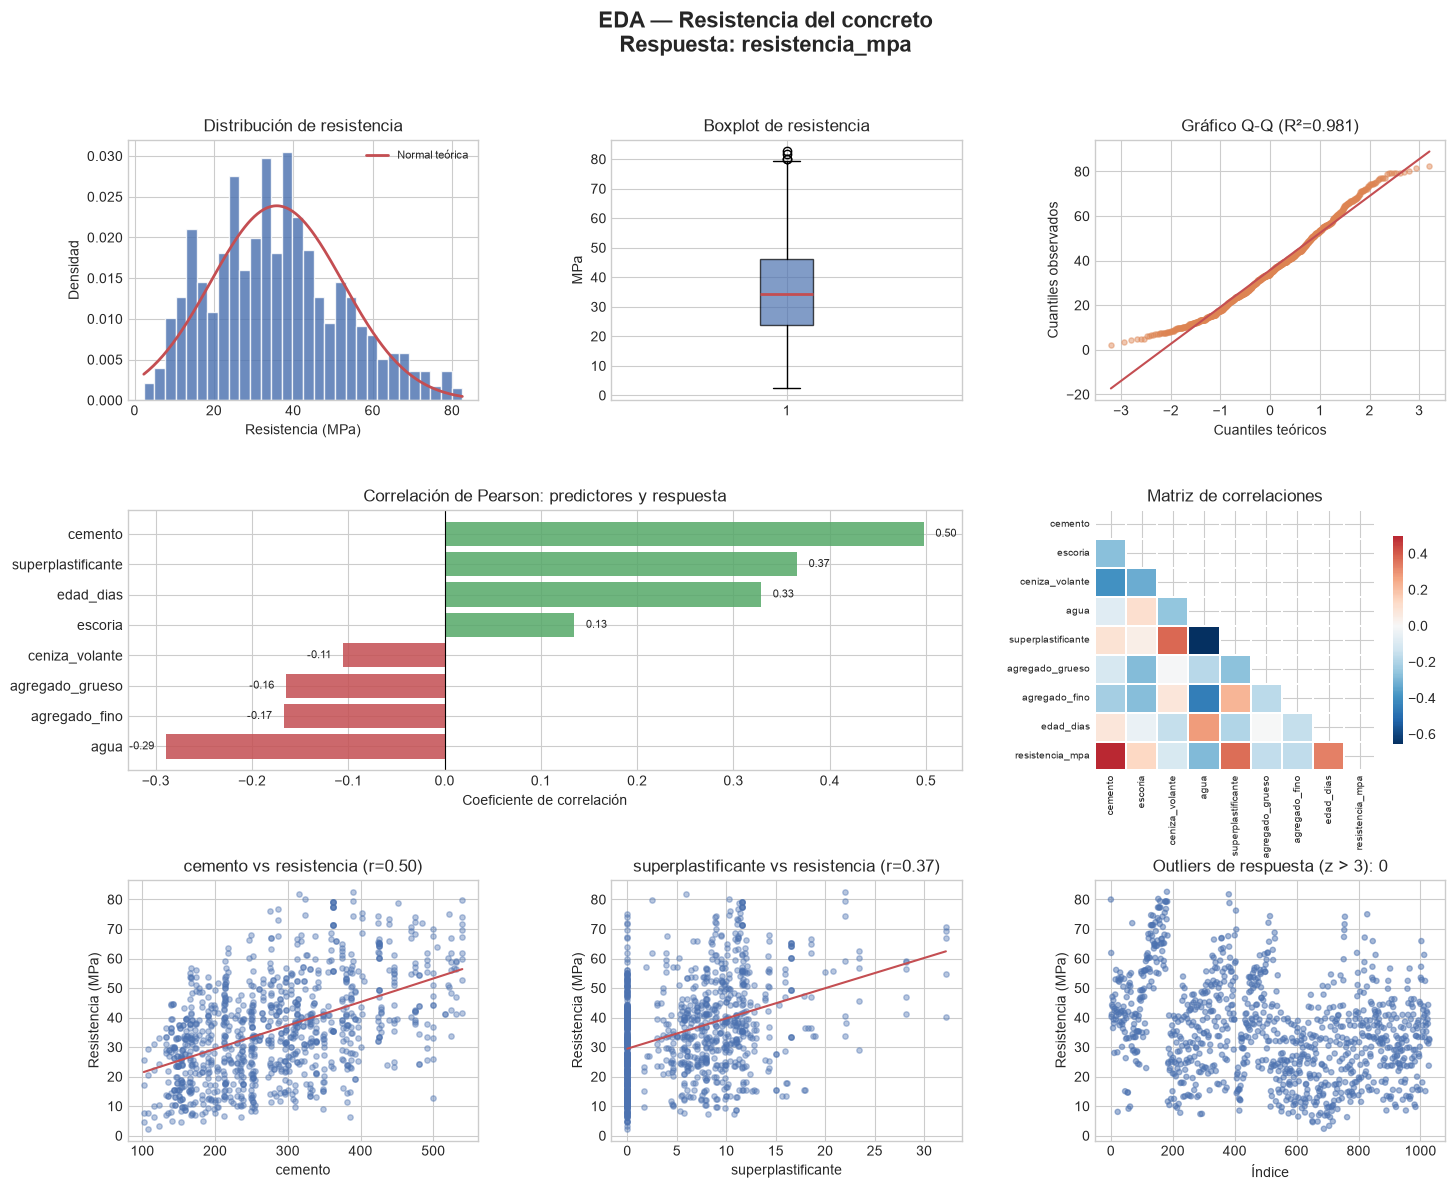

In [3]:
print("=" * 58)
print("ANÁLISIS DE LA VARIABLE RESPUESTA: resistencia_mpa")
print("=" * 58)
print(f"Media    : {df[TARGET].mean():.3f} MPa")
print(f"Mediana  : {df[TARGET].median():.3f} MPa")
print(f"Desv. estándar: {df[TARGET].std():.3f} MPa")
print(f"Mínimo   : {df[TARGET].min():.3f} MPa")
print(f"Máximo   : {df[TARGET].max():.3f} MPa")
print(f"Asimetría: {df[TARGET].skew():.4f}")
print(f"Curtosis : {df[TARGET].kurt():.4f}")

fig = plt.figure(figsize=(17, 13))
gs = gridspec.GridSpec(3, 3, figure=fig, hspace=0.42, wspace=0.38)
fig.suptitle(
    "EDA — Resistencia del concreto\nRespuesta: resistencia_mpa",
    fontsize=16,
    fontweight="bold",
)

ax1 = fig.add_subplot(gs[0, 0])
ax1.hist(df[TARGET], bins=30, color="#4C72B0", edgecolor="white", alpha=0.82, density=True)
x_normal = np.linspace(df[TARGET].min(), df[TARGET].max(), 200)
ax1.plot(x_normal, stats.norm.pdf(x_normal, df[TARGET].mean(), df[TARGET].std()),
         color="#C44E52", linewidth=2, label="Normal teórica")
ax1.set(title="Distribución de resistencia", xlabel="Resistencia (MPa)", ylabel="Densidad")
ax1.legend(fontsize=8)

ax2 = fig.add_subplot(gs[0, 1])
ax2.boxplot(
    df[TARGET],
    vert=True,
    patch_artist=True,
    boxprops=dict(facecolor="#4C72B0", alpha=0.7),
    medianprops=dict(color="#C44E52", linewidth=2),
)
ax2.set(title="Boxplot de resistencia", ylabel="MPa")

ax3 = fig.add_subplot(gs[0, 2])
(osm, osr), (slope, intercept, r_value) = stats.probplot(df[TARGET], dist="norm")
ax3.scatter(osm, osr, alpha=0.45, s=14, color="#DD8452")
ax3.plot(osm, slope * np.asarray(osm) + intercept, color="#C44E52", linewidth=1.5)
ax3.set(title=f"Gráfico Q-Q (R²={r_value**2:.3f})",
        xlabel="Cuantiles teóricos", ylabel="Cuantiles observados")

corr = df.corr(numeric_only=True)
corr_target = corr[TARGET].drop(TARGET).sort_values()
ax4 = fig.add_subplot(gs[1, :2])
bar_colors = ["#C44E52" if value < 0 else "#55A868" for value in corr_target]
bars = ax4.barh(corr_target.index, corr_target.values, color=bar_colors, alpha=0.85)
ax4.axvline(0, color="black", linewidth=0.8)
ax4.set(title="Correlación de Pearson: predictores y respuesta",
        xlabel="Coeficiente de correlación")
for bar, value in zip(bars, corr_target.values):
    ax4.text(value + (0.012 if value >= 0 else -0.012),
             bar.get_y() + bar.get_height() / 2, f"{value:.2f}",
             va="center", ha="left" if value >= 0 else "right", fontsize=8)

ax5 = fig.add_subplot(gs[1, 2])
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, ax=ax5, cmap="RdBu_r", center=0,
            annot=False, linewidths=0.25, cbar_kws={"shrink": 0.8})
ax5.set_title("Matriz de correlaciones")
ax5.tick_params(labelsize=7)

top_features = corr_target.abs().sort_values(ascending=False).head(2).index.tolist()
for ax, feature in zip((fig.add_subplot(gs[2, 0]), fig.add_subplot(gs[2, 1])), top_features):
    ax.scatter(df[feature], df[TARGET], alpha=0.4, color="#4C72B0", s=15)
    slope, intercept, r_value, _, _ = stats.linregress(df[feature], df[TARGET])
    x_line = np.linspace(df[feature].min(), df[feature].max(), 100)
    ax.plot(x_line, slope * x_line + intercept, color="#C44E52", linewidth=1.5)
    ax.set(title=f"{feature} vs resistencia (r={r_value:.2f})",
           xlabel=feature, ylabel="Resistencia (MPa)")

ax8 = fig.add_subplot(gs[2, 2])
z_scores = np.abs(stats.zscore(df[TARGET]))
outlier_mask = z_scores > 3
ax8.scatter(range(len(df)), df[TARGET],
            c=np.where(outlier_mask, "#C44E52", "#4C72B0"), alpha=0.5, s=14)
ax8.set(title=f"Outliers de respuesta (z > 3): {outlier_mask.sum()}",
        xlabel="Índice", ylabel="Resistencia (MPa)")
plt.show()

## 03 — Preprocesamiento y partición 80/20

In [4]:
X = df[FEATURES].copy()
y = df[TARGET].copy()

print("=" * 58)
print("REVISIÓN DE OUTLIERS POR PREDICTOR (z-score > 3)")
print("=" * 58)
for columna in FEATURES:
    cantidad = int((np.abs(stats.zscore(X[columna])) > 3).sum())
    if cantidad:
        print(f"{columna:<22}: {cantidad}")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED
)
print(f"\nEntrenamiento: {len(X_train)} observaciones ({len(X_train) / len(df):.0%})")
print(f"Prueba       : {len(X_test)} observaciones ({len(X_test) / len(df):.0%})")
print(f"Media de resistencia — train: {y_train.mean():.3f} | test: {y_test.mean():.3f} MPa")
print(f"Desv. estándar — train: {y_train.std():.3f} | test: {y_test.std():.3f} MPa")

REVISIÓN DE OUTLIERS POR PREDICTOR (z-score > 3)
escoria               : 4
agua                  : 2
superplastificante    : 10
edad_dias             : 33

Entrenamiento: 824 observaciones (80%)
Prueba       : 206 observaciones (20%)
Media de resistencia — train: 35.858 | test: 35.658 MPa
Desv. estándar — train: 16.865 | test: 16.092 MPa


## 04 — Función de evaluación

In [5]:
def evaluar_modelo(nombre, y_real, y_estimado, verbose=True):
    """Calcula RMSE, MAE, MAPE, R² y R² ajustado para una respuesta cuantitativa."""
    n = len(y_real)
    p = X_train.shape[1]
    rmse = np.sqrt(mean_squared_error(y_real, y_estimado))
    mae = mean_absolute_error(y_real, y_estimado)
    mape = mean_absolute_percentage_error(y_real, y_estimado) * 100
    r2 = r2_score(y_real, y_estimado)
    r2_ajustado = 1 - (1 - r2) * (n - 1) / (n - p - 1)
    if verbose:
        print(f"\n{'=' * 52}\n{nombre}\n{'=' * 52}")
        print(f"RMSE     : {rmse:.4f} MPa")
        print(f"MAE      : {mae:.4f} MPa")
        print(f"MAPE     : {mape:.2f}%")
        print(f"R²       : {r2:.4f} ({r2 * 100:.1f}% de varianza explicada)")
        print(f"R² ajust.: {r2_ajustado:.4f}")
    return {"RMSE": rmse, "MAE": mae, "MAPE": mape, "R2": r2, "R2_ajustado": r2_ajustado}

## 05 — Modelo base

In [6]:
print("MODELO BASE")
rf_base = RandomForestRegressor(
    n_estimators=10,
    criterion="squared_error",
    max_depth=None,
    max_features=1,
    oob_score=False,
    n_jobs=2,
    random_state=123,
)
rf_base.fit(X_train, y_train)
print("Bosque base entrenado con 10 árboles y un predictor candidato por división.")

MODELO BASE
Bosque base entrenado con 10 árboles y un predictor candidato por división.


## 06 — Predicción, métricas y validación cruzada del modelo base

In [7]:
y_pred_base = rf_base.predict(X_test)
metricas_base = evaluar_modelo("Random Forest BASE — conjunto de prueba", y_test, y_pred_base)

cv_r2 = cross_val_score(rf_base, X, y, cv=5, scoring="r2", n_jobs=2)
cv_rmse = cross_val_score(
    rf_base, X, y, cv=5, scoring="neg_root_mean_squared_error", n_jobs=2
)
print(f"\nCV R² (5-fold): {cv_r2.mean():.4f} ± {cv_r2.std():.4f}")
print(f"CV RMSE (5-fold): {(-cv_rmse).mean():.4f} ± {(-cv_rmse).std():.4f} MPa")


Random Forest BASE — conjunto de prueba
RMSE     : 7.0614 MPa
MAE      : 5.3760 MPa
MAPE     : 20.01%
R²       : 0.8065 (80.6% de varianza explicada)
R² ajust.: 0.7986



CV R² (5-fold): 0.1490 ± 0.9201
CV RMSE (5-fold): 11.9756 ± 4.4131 MPa


## 07 — Validación Out-of-Bag (OOB) según número de árboles

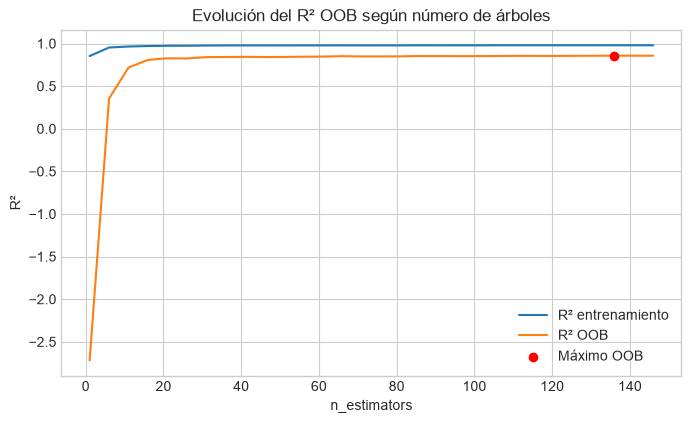

Mejor n_estimators por OOB: 136


In [8]:
train_scores_oob = []
oob_scores = []
estimator_range = range(1, 150, 5)
for n_estimators in estimator_range:
    modelo = RandomForestRegressor(
        n_estimators=n_estimators,
        criterion="squared_error",
        max_depth=None,
        max_features=1,
        oob_score=True,
        n_jobs=2,
        random_state=123,
    )
    modelo.fit(X_train, y_train)
    train_scores_oob.append(modelo.score(X_train, y_train))
    oob_scores.append(modelo.oob_score_)

validos_oob = np.flatnonzero(np.isfinite(oob_scores))
if len(validos_oob) == 0:
    raise RuntimeError("No se obtuvo ningún puntaje OOB finito.")
mejor_oob_idx = validos_oob[np.argmax(np.asarray(oob_scores)[validos_oob])]
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(list(estimator_range), train_scores_oob, label="R² entrenamiento")
ax.plot(list(estimator_range), oob_scores, label="R² OOB")
ax.scatter(list(estimator_range)[mejor_oob_idx], oob_scores[mejor_oob_idx],
           color="red", label="Máximo OOB", zorder=3)
ax.set(title="Evolución del R² OOB según número de árboles",
       xlabel="n_estimators", ylabel="R²")
ax.legend()
plt.show()
print(f"Mejor n_estimators por OOB: {list(estimator_range)[mejor_oob_idx]}")

## 08 — Validación cruzada según número de árboles

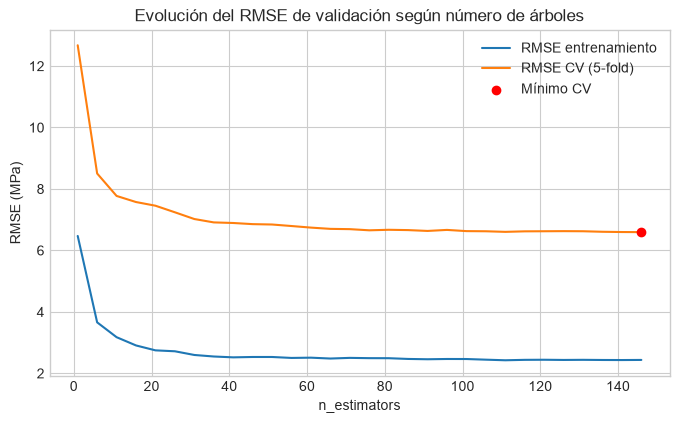

Mejor n_estimators por CV: 146


In [9]:
train_rmse_trees = []
cv_rmse_trees = []
for n_estimators in estimator_range:
    modelo = RandomForestRegressor(
        n_estimators=n_estimators,
        criterion="squared_error",
        max_depth=None,
        max_features=1,
        oob_score=False,
        n_jobs=2,
        random_state=123,
    )
    modelo.fit(X_train, y_train)
    pred_train = modelo.predict(X_train)
    train_rmse_trees.append(np.sqrt(mean_squared_error(y_train, pred_train)))
    scores = cross_val_score(
        modelo,
        X_train,
        y_train,
        scoring="neg_root_mean_squared_error",
        cv=5,
    )
    cv_rmse_trees.append(-scores.mean())

mejor_cv_idx = int(np.argmin(cv_rmse_trees))
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(list(estimator_range), train_rmse_trees, label="RMSE entrenamiento")
ax.plot(list(estimator_range), cv_rmse_trees, label="RMSE CV (5-fold)")
ax.scatter(list(estimator_range)[mejor_cv_idx], cv_rmse_trees[mejor_cv_idx],
           color="red", label="Mínimo CV", zorder=3)
ax.set(title="Evolución del RMSE de validación según número de árboles",
       xlabel="n_estimators", ylabel="RMSE (MPa)")
ax.legend()
plt.show()
print(f"Mejor n_estimators por CV: {list(estimator_range)[mejor_cv_idx]}")

## 09 — Optimización de hiperparámetros con GridSearchCV

In [10]:
print("=" * 58)
print("OPTIMIZACIÓN DE HIPERPARÁMETROS")
print("Estrategia: GridSearchCV | Pliegues: 5 | Métrica: neg_root_mean_squared_error")
param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [None, 10, 20],
    "max_features": ["sqrt", "log2", 0.5],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "bootstrap": [True],
}
n_combinaciones = int(np.prod([len(valores) for valores in param_grid.values()]))
print(f"Combinaciones: {n_combinaciones} | Ajustes CV: {n_combinaciones * 5}")

rf_grid = GridSearchCV(
    estimator=RandomForestRegressor(random_state=SEED, n_jobs=2),
    param_grid=param_grid,
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=2,
    verbose=0,
    refit=True,
)
rf_grid.fit(X_train, y_train)
print("\nMejores hiperparámetros:")
for parametro, valor in rf_grid.best_params_.items():
    print(f"  {parametro:<22}: {valor}")
print(f"Mejor RMSE de validación: {-rf_grid.best_score_:.4f} MPa")

OPTIMIZACIÓN DE HIPERPARÁMETROS
Estrategia: GridSearchCV | Pliegues: 5 | Métrica: neg_root_mean_squared_error
Combinaciones: 243 | Ajustes CV: 1215



Mejores hiperparámetros:
  bootstrap             : True
  max_depth             : 20
  max_features          : 0.5
  min_samples_leaf      : 1
  min_samples_split     : 2
  n_estimators          : 300
Mejor RMSE de validación: 5.1145 MPa


## 10 — Evaluación del modelo optimizado y comparación

In [11]:
best_rf = rf_grid.best_estimator_
y_pred_opt = best_rf.predict(X_test)
metricas_opt = evaluar_modelo("Random Forest OPTIMIZADO — conjunto de prueba", y_test, y_pred_opt)
cv_r2_opt = cross_val_score(best_rf, X, y, cv=5, scoring="r2", n_jobs=2)
print(f"\nCV R² del modelo optimizado (5-fold): {cv_r2_opt.mean():.4f} ± {cv_r2_opt.std():.4f}")

filas_comparacion = []
for metrica in ["RMSE", "MAE", "MAPE", "R2", "R2_ajustado"]:
    base = metricas_base[metrica]
    optimizado = metricas_opt[metrica]
    delta = optimizado - base if metrica.startswith("R2") else base - optimizado
    filas_comparacion.append({
        "Métrica": metrica,
        "Base": base,
        "Optimizado": optimizado,
        "Diferencia favorable": delta,
    })
comparacion = pd.DataFrame(filas_comparacion)
display(comparacion.round(4))


Random Forest OPTIMIZADO — conjunto de prueba
RMSE     : 5.3404 MPa
MAE      : 3.7108 MPa
MAPE     : 12.26%
R²       : 0.8893 (88.9% de varianza explicada)
R² ajust.: 0.8848



CV R² del modelo optimizado (5-fold): 0.4269 ± 0.6722


,Métrica,Base,Optimizado,Diferencia favorable
0,RMSE,7.0614,5.3404,1.7210
1,MAE,5.3760,3.7108,1.6652
2,MAPE,20.0135,12.2573,7.7561
3,R2,0.8065,0.8893,0.0828
4,R2_ajustado,0.7986,0.8848,0.0862


## 11 — Importancia de variables

,Importancia por impureza,Aumento RMSE por permutación,Desv. permutación
edad_dias,0.3348,9.8585,0.3128
cemento,0.2639,5.8977,0.3789
agua,0.1295,3.6386,0.2072
superplastificante,0.0722,1.9488,0.1536
escoria,0.0648,1.8674,0.1310
agregado_fino,0.0510,0.9615,0.1620
agregado_grueso,0.0426,0.3400,0.0453
ceniza_volante,0.0411,0.1882,0.0808


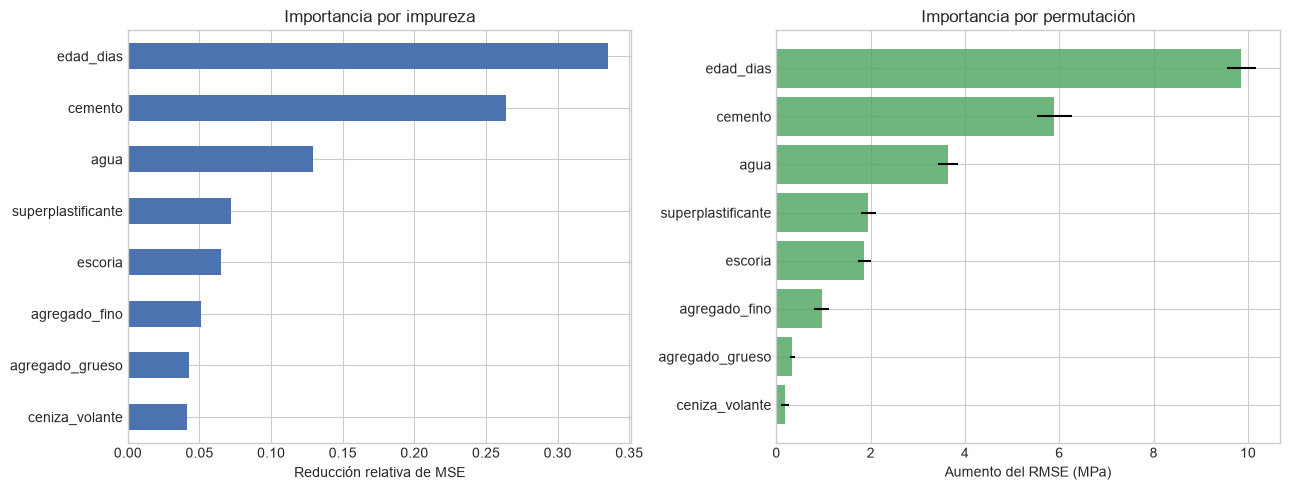

In [12]:
importancia_impureza = pd.Series(best_rf.feature_importances_, index=FEATURES).sort_values(ascending=False)
perm = permutation_importance(
    best_rf, X_test, y_test, n_repeats=10, random_state=SEED,
    scoring="neg_root_mean_squared_error", n_jobs=2,
)
importancia_permutacion = pd.Series(perm.importances_mean, index=FEATURES).sort_values(ascending=False)
tabla_importancia = pd.DataFrame({
    "Importancia por impureza": importancia_impureza,
    "Aumento RMSE por permutación": pd.Series(perm.importances_mean, index=FEATURES),
    "Desv. permutación": pd.Series(perm.importances_std, index=FEATURES),
}).sort_values("Importancia por impureza", ascending=False)
display(tabla_importancia.round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
importancia_impureza.sort_values().plot.barh(ax=axes[0], color="#4C72B0")
axes[0].set(title="Importancia por impureza", xlabel="Reducción relativa de MSE")
orden_perm = np.argsort(perm.importances_mean)
axes[1].barh(np.asarray(FEATURES)[orden_perm],
             perm.importances_mean[orden_perm],
             xerr=perm.importances_std[orden_perm],
             color="#55A868", alpha=0.85)
axes[1].set(title="Importancia por permutación",
            xlabel="Aumento del RMSE (MPa)")
plt.tight_layout()
plt.show()

## 12 — Visualizaciones finales y curvas de aprendizaje

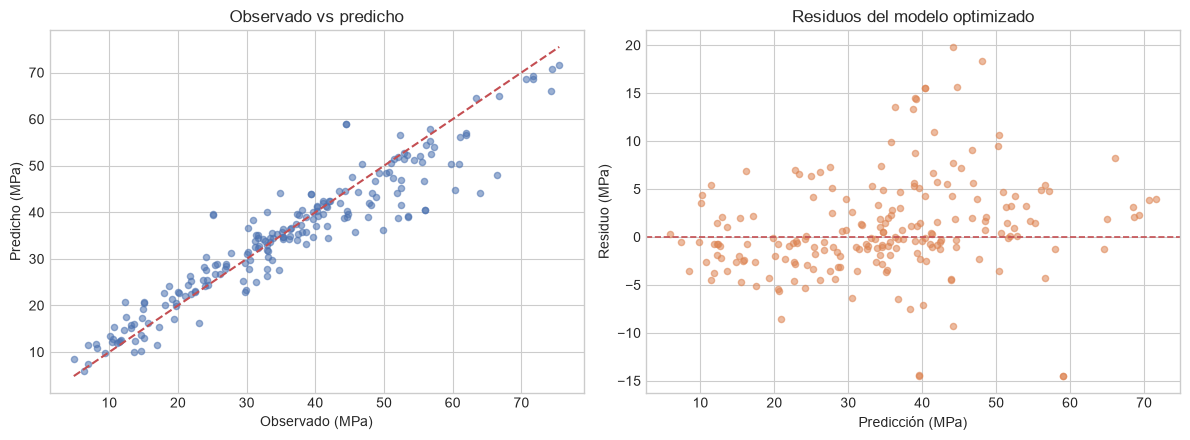

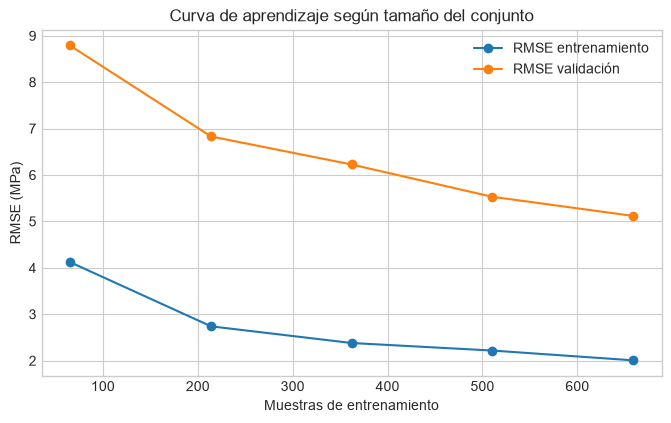

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(y_test, y_pred_opt, alpha=0.55, color="#4C72B0", s=20)
limites = [min(y_test.min(), y_pred_opt.min()), max(y_test.max(), y_pred_opt.max())]
axes[0].plot(limites, limites, "--", color="#C44E52", linewidth=1.5)
axes[0].set(title="Observado vs predicho", xlabel="Observado (MPa)", ylabel="Predicho (MPa)")

residuos = y_test - y_pred_opt
axes[1].scatter(y_pred_opt, residuos, alpha=0.55, color="#DD8452", s=20)
axes[1].axhline(0, color="#C44E52", linestyle="--", linewidth=1.2)
axes[1].set(title="Residuos del modelo optimizado",
            xlabel="Predicción (MPa)", ylabel="Residuo (MPa)")
plt.tight_layout()
plt.show()

tam_train, score_train, score_cv = learning_curve(
    best_rf, X_train, y_train, cv=5,
    scoring="neg_root_mean_squared_error",
    train_sizes=np.linspace(0.1, 1.0, 5),
    n_jobs=2,
)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(tam_train, -score_train.mean(axis=1), marker="o", label="RMSE entrenamiento")
ax.plot(tam_train, -score_cv.mean(axis=1), marker="o", label="RMSE validación")
ax.set(title="Curva de aprendizaje según tamaño del conjunto",
       xlabel="Muestras de entrenamiento", ylabel="RMSE (MPa)")
ax.legend()
plt.show()

## 13 — Interpretación y resumen

In [14]:
mejor_variable = importancia_impureza.index[0]
mejora_rmse = (metricas_base["RMSE"] - metricas_opt["RMSE"]) / metricas_base["RMSE"] * 100
print("RESUMEN DEL MODELO RANDOM FOREST")
print(f"Predictores usados: {len(FEATURES)} | Observaciones: {len(df)}")
print(f"RMSE de prueba, modelo base: {metricas_base['RMSE']:.3f} MPa")
print(f"RMSE de prueba, optimizado: {metricas_opt['RMSE']:.3f} MPa")
print(f"Cambio de RMSE frente al modelo base: {mejora_rmse:+.2f}%")
print(f"Variable con mayor importancia por impureza: {mejor_variable}")
print("La importancia describe contribución predictiva dentro del modelo, no causalidad.")

RESUMEN DEL MODELO RANDOM FOREST
Predictores usados: 8 | Observaciones: 1030
RMSE de prueba, modelo base: 7.061 MPa
RMSE de prueba, optimizado: 5.340 MPa
Cambio de RMSE frente al modelo base: +24.37%
Variable con mayor importancia por impureza: edad_dias
La importancia describe contribución predictiva dentro del modelo, no causalidad.


## 14 — Función para predicción individual y dispersión entre árboles

In [15]:
def predecir_resistencia(modelo, datos_entrada, nombres_features):
    """Resume las predicciones de los árboles; el rango describe dispersión, no IC calibrado."""
    if isinstance(datos_entrada, dict):
        datos = pd.DataFrame([datos_entrada])
    else:
        datos = datos_entrada.copy()
    datos = datos[nombres_features]
    predicciones_arboles = np.asarray([
        arbol.predict(datos) for arbol in modelo.estimators_
    ])
    media = predicciones_arboles.mean(axis=0)
    desviacion = predicciones_arboles.std(axis=0)
    p05 = np.percentile(predicciones_arboles, 5, axis=0)
    p25 = np.percentile(predicciones_arboles, 25, axis=0)
    p75 = np.percentile(predicciones_arboles, 75, axis=0)
    p95 = np.percentile(predicciones_arboles, 95, axis=0)
    cv_modelo = np.divide(desviacion, np.maximum(np.abs(media), 1e-9)) * 100
    confianza = np.where(cv_modelo < 5, "Alta",
                         np.where(cv_modelo < 15, "Media", "Baja"))
    resultados = pd.DataFrame({
        "Predicción (MPa)": media.round(3),
        "Percentil 5 entre árboles": p05.round(3),
        "Percentil 95 entre árboles": p95.round(3),
        "Q25 entre árboles": p25.round(3),
        "Q75 entre árboles": p75.round(3),
        "Desv. entre árboles": desviacion.round(3),
        "CV entre árboles (%)": cv_modelo.round(2),
        "Acuerdo entre árboles": confianza,
    })
    return resultados, predicciones_arboles

## 15 — Caso 1: predicción de una mezcla individual

Mezcla ilustrativa con valores medianos de los predictores:


,cemento,escoria,ceniza_volante,agua,superplastificante,agregado_grueso,agregado_fino,edad_dias
0,272.9,22.0,0.0,185.0,6.35,968.0,779.51,28.0


,Predicción (MPa),Percentil 5 entre árboles,Percentil 95 entre árboles,Q25 entre árboles,Q75 entre árboles,Desv. entre árboles,CV entre árboles (%),Acuerdo entre árboles
0,36.452,24.497,47.422,30.234,42.637,8.152,22.36,Baja


La dispersión se calcula entre árboles y no constituye un intervalo de confianza calibrado.


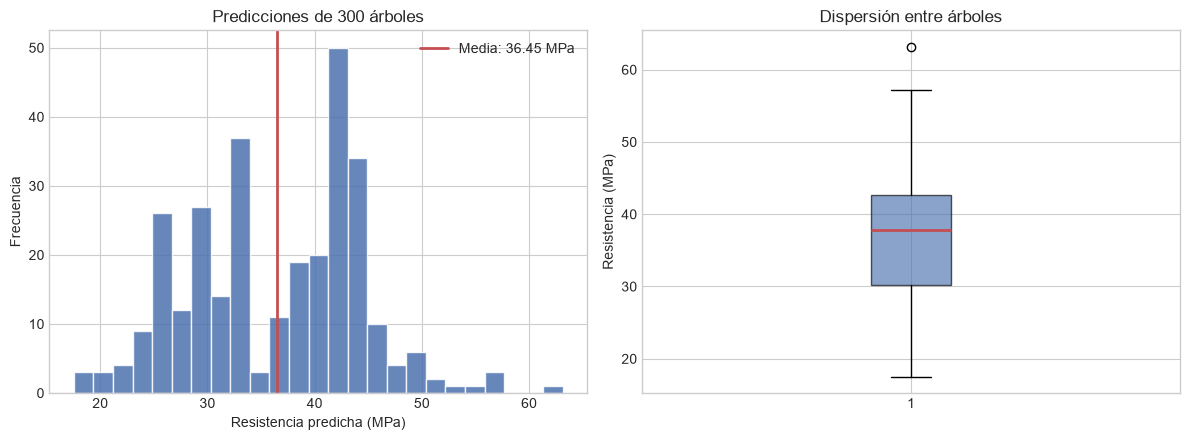

In [16]:
mezcla_nueva = X.median().to_frame().T
resultado_individual, distribucion_individual = predecir_resistencia(
    best_rf, mezcla_nueva, FEATURES
)
print("Mezcla ilustrativa con valores medianos de los predictores:")
display(mezcla_nueva.round(2))
display(resultado_individual)
print("La dispersión se calcula entre árboles y no constituye un intervalo de confianza calibrado.")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
predicciones = distribucion_individual[:, 0]
axes[0].hist(predicciones, bins=25, color="#4C72B0", edgecolor="white", alpha=0.85)
axes[0].axvline(np.mean(predicciones), color="#C44E52", linewidth=2,
                label=f"Media: {np.mean(predicciones):.2f} MPa")
axes[0].set(title=f"Predicciones de {len(predicciones)} árboles",
            xlabel="Resistencia predicha (MPa)", ylabel="Frecuencia")
axes[0].legend()
axes[1].boxplot(predicciones, patch_artist=True,
                boxprops=dict(facecolor="#4C72B0", alpha=0.65),
                medianprops=dict(color="#C44E52", linewidth=2))
axes[1].set(title="Dispersión entre árboles", ylabel="Resistencia (MPa)")
plt.tight_layout()
plt.show()

## 16 — Caso 2: comparación de perfiles de mezcla

,Predicción (MPa),Percentil 5 entre árboles,Percentil 95 entre árboles,Q25 entre árboles,Q75 entre árboles,Desv. entre árboles,CV entre árboles (%),Acuerdo entre árboles
0,21.546,8.348,42.796,13.624,25.422,11.445,53.12,Baja
1,36.452,24.497,47.422,30.234,42.637,8.152,22.36,Baja
2,49.820,32.047,74.775,39.383,59.146,13.719,27.54,Baja


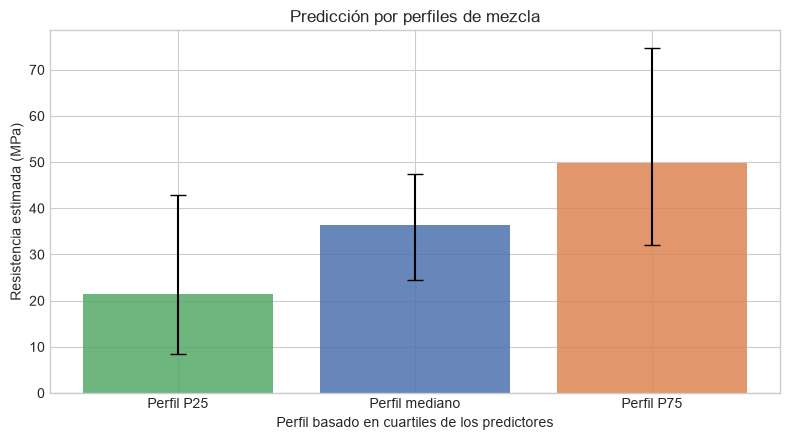

In [17]:
cuartiles = X.quantile([0.25, 0.50, 0.75])
escenarios = cuartiles.copy()
escenarios.index = ["Perfil P25", "Perfil mediano", "Perfil P75"]
resultados_escenarios, dist_escenarios = predecir_resistencia(best_rf, escenarios, FEATURES)
display(resultados_escenarios)

fig, ax = plt.subplots(figsize=(8, 4.5))
pred = resultados_escenarios["Predicción (MPa)"].to_numpy()
inf = resultados_escenarios["Percentil 5 entre árboles"].to_numpy()
sup = resultados_escenarios["Percentil 95 entre árboles"].to_numpy()
ax.bar(escenarios.index, pred, color=["#55A868", "#4C72B0", "#DD8452"],
       alpha=0.85, yerr=[pred - inf, sup - pred], capsize=6,
       error_kw={"ecolor": "black", "elinewidth": 1.5})
ax.set(title="Predicción por perfiles de mezcla",
       xlabel="Perfil basado en cuartiles de los predictores",
       ylabel="Resistencia estimada (MPa)")
plt.tight_layout()
plt.show()

## 17 — Caso 3: predicción en lote

,ID_observación,Predicción (MPa),Percentil 5 entre árboles,Percentil 95 entre árboles,Q25 entre árboles,Q75 entre árboles,Desv. entre árboles,CV entre árboles (%),Acuerdo entre árboles
0,LOTE_01,22.502,13.089,25.894,20.416,25.422,4.727,21.01,Baja
1,LOTE_02,43.322,29.392,52.918,38.997,48.794,8.129,18.76,Baja
2,LOTE_03,54.530,46.622,61.460,54.765,55.255,4.243,7.78,Media
3,LOTE_04,36.969,29.585,50.459,32.103,38.469,6.342,17.15,Baja
4,LOTE_05,31.208,22.835,39.645,29.232,34.557,5.016,16.07,Baja
5,LOTE_06,35.801,19.973,50.773,30.385,40.231,8.231,22.99,Baja
6,LOTE_07,30.498,23.787,37.363,28.986,32.840,4.727,15.50,Baja
7,LOTE_08,52.378,42.621,55.064,52.517,53.104,2.931,5.60,Media
8,LOTE_09,7.422,2.332,12.788,4.565,9.695,4.240,57.13,Baja
9,LOTE_10,33.928,27.308,43.058,31.350,38.893,5.212,15.36,Baja


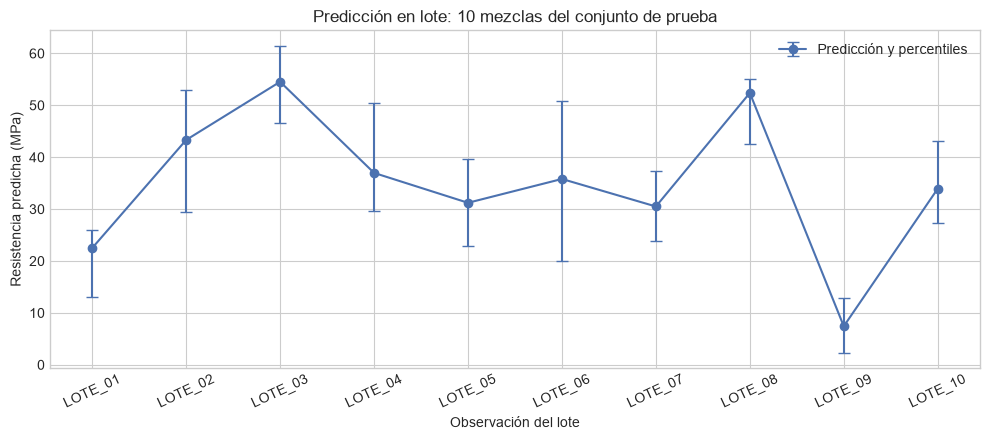

In [18]:
lote = X_test.sample(n=min(10, len(X_test)), random_state=SEED)
resultados_lote, dist_lote = predecir_resistencia(best_rf, lote, FEATURES)
resultados_lote.insert(0, "ID_observación", [f"LOTE_{i:02d}" for i in range(1, len(lote) + 1)])
display(resultados_lote)

fig, ax = plt.subplots(figsize=(10, 4.5))
posiciones = np.arange(len(resultados_lote))
pred_lote = resultados_lote["Predicción (MPa)"].to_numpy()
ax.errorbar(posiciones, pred_lote,
            yerr=[
                pred_lote - resultados_lote["Percentil 5 entre árboles"].to_numpy(),
                resultados_lote["Percentil 95 entre árboles"].to_numpy() - pred_lote,
            ],
            fmt="o-", color="#4C72B0", capsize=4, label="Predicción y percentiles")
ax.set(title="Predicción en lote: 10 mezclas del conjunto de prueba",
       xlabel="Observación del lote", ylabel="Resistencia predicha (MPa)")
ax.set_xticks(posiciones, resultados_lote["ID_observación"], rotation=25)
ax.legend()
plt.tight_layout()
plt.show()

## 18 — Caso 4: análisis de sensibilidad

Resistencia predicha para la mezcla mediana: 36.452 MPa


,Predictor,Cambio +20% (MPa),Cambio -20% (MPa),Rango de impacto (MPa)
3,agua,-2.336,16.536,18.872
0,cemento,5.854,-6.464,12.318
5,agregado_grueso,-2.131,5.046,7.177
6,agregado_fino,-1.356,2.802,4.158
4,superplastificante,0.031,-1.636,1.667
1,escoria,0.119,-0.094,0.213
2,ceniza_volante,0.000,0.000,0.000
7,edad_dias,0.000,0.000,0.000


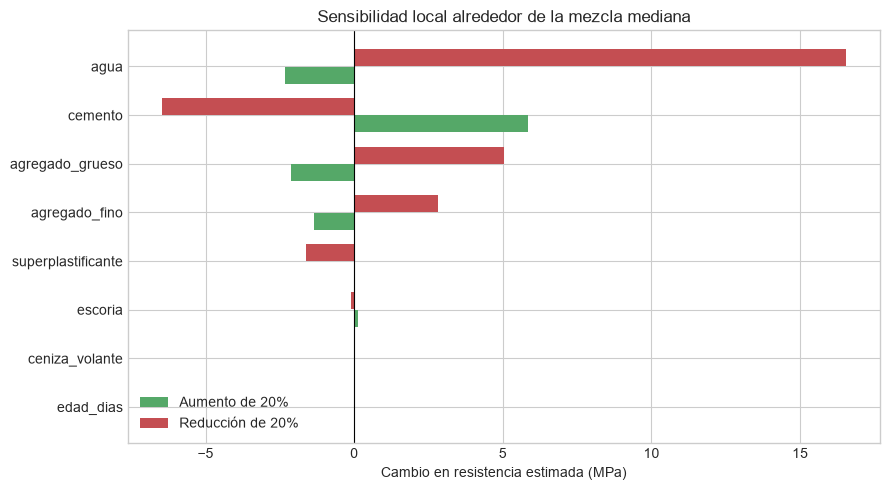

In [19]:
base_mezcla = X.median().to_dict()
pred_base_mezcla = best_rf.predict(pd.DataFrame([base_mezcla])[FEATURES])[0]
registros_sensibilidad = []
for feature in FEATURES:
    valor = base_mezcla[feature]
    caso_arriba = base_mezcla.copy()
    caso_abajo = base_mezcla.copy()
    caso_arriba[feature] = np.clip(valor * 1.20, X_train[feature].min(), X_train[feature].max())
    caso_abajo[feature] = np.clip(valor * 0.80, X_train[feature].min(), X_train[feature].max())
    pred_arriba = best_rf.predict(pd.DataFrame([caso_arriba])[FEATURES])[0]
    pred_abajo = best_rf.predict(pd.DataFrame([caso_abajo])[FEATURES])[0]
    registros_sensibilidad.append({
        "Predictor": feature,
        "Cambio +20% (MPa)": pred_arriba - pred_base_mezcla,
        "Cambio -20% (MPa)": pred_abajo - pred_base_mezcla,
        "Rango de impacto (MPa)": abs(pred_arriba - pred_abajo),
    })
df_sensibilidad = pd.DataFrame(registros_sensibilidad).sort_values(
    "Rango de impacto (MPa)", ascending=False
)
print(f"Resistencia predicha para la mezcla mediana: {pred_base_mezcla:.3f} MPa")
display(df_sensibilidad.round(3))

fig, ax = plt.subplots(figsize=(9, 5))
orden = df_sensibilidad.sort_values("Rango de impacto (MPa)")
pos = np.arange(len(orden))
ax.barh(pos - 0.18, orden["Cambio +20% (MPa)"], height=0.35,
        color="#55A868", label="Aumento de 20%")
ax.barh(pos + 0.18, orden["Cambio -20% (MPa)"], height=0.35,
        color="#C44E52", label="Reducción de 20%")
ax.axvline(0, color="black", linewidth=0.8)
ax.set_yticks(pos, orden["Predictor"])
ax.set(title="Sensibilidad local alrededor de la mezcla mediana",
       xlabel="Cambio en resistencia estimada (MPa)")
ax.legend()
plt.tight_layout()
plt.show()

## 19 — Búsqueda bayesiana complementaria con Optuna

In [20]:
import optuna

def objetivo(trial):
    parametros = {
        "n_estimators": trial.suggest_int("n_estimators", 100, 1000, step=100),
        "max_depth": trial.suggest_int("max_depth", 3, 30),
        "min_samples_split": trial.suggest_int("min_samples_split", 2, 100),
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 100),
        "max_features": trial.suggest_float("max_features", 0.2, 1.0),
        "ccp_alpha": trial.suggest_float("ccp_alpha", 0.0, 1.0),
        "n_jobs": 2,
        "random_state": 4576688,
    }
    modelo = RandomForestRegressor(**parametros)
    puntajes = cross_val_score(
        modelo,
        X_train,
        y_train,
        cv=RepeatedKFold(n_splits=5, n_repeats=3, random_state=123),
        scoring="neg_root_mean_squared_error",
        n_jobs=2,
    )
    return float(np.mean(puntajes))

study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=42))
study.optimize(objetivo, n_trials=30, show_progress_bar=False, timeout=60 * 5)
print("Mejores hiperparámetros de Optuna:")
for parametro, valor in study.best_params.items():
    print(f"  {parametro:<22}: {valor}")
print(f"Mejor RMSE medio en CV: {-study.best_value:.4f} MPa")
print("La búsqueda bayesiana es complementaria; el modelo evaluado en las secciones anteriores proviene de GridSearchCV.")

[I 2026-10-18 01:23:29,588] A new study created in memory with name: no-name-e5c13f5d-16ce-4dac-86b2-05f04f592f5d


[I 2026-10-18 01:23:32,343] Trial 0 finished with value: -12.00109964625388 and parameters: {'n_estimators': 400, 'max_depth': 29, 'min_samples_split': 74, 'min_samples_leaf': 60, 'max_features': 0.3248149123539492, 'ccp_alpha': 0.15599452033620265}. Best is trial 0 with value: -12.00109964625388.


[I 2026-10-18 01:23:33,141] Trial 1 finished with value: -13.71096051295219 and parameters: {'n_estimators': 100, 'max_depth': 27, 'min_samples_split': 61, 'min_samples_leaf': 71, 'max_features': 0.21646759543664196, 'ccp_alpha': 0.9699098521619943}. Best is trial 0 with value: -12.00109964625388.


[I 2026-10-18 01:23:39,380] Trial 2 finished with value: -8.362394984537493 and parameters: {'n_estimators': 900, 'max_depth': 8, 'min_samples_split': 20, 'min_samples_leaf': 19, 'max_features': 0.4433937943676302, 'ccp_alpha': 0.5247564316322378}. Best is trial 2 with value: -8.362394984537493.


[I 2026-10-18 01:23:42,884] Trial 3 finished with value: -8.751328328413292 and parameters: {'n_estimators': 500, 'max_depth': 11, 'min_samples_split': 62, 'min_samples_leaf': 14, 'max_features': 0.43371571882817456, 'ccp_alpha': 0.3663618432936917}. Best is trial 2 with value: -8.362394984537493.


...

[I 2026-10-18 01:25:47,560] Trial 26 finished with value: -6.267270068936823 and parameters: {'n_estimators': 800, 'max_depth': 19, 'min_samples_split': 9, 'min_samples_leaf': 6, 'max_features': 0.8003402383699603, 'ccp_alpha': 0.1413012633279492}. Best is trial 25 with value: -6.059501046583523.


[I 2026-10-18 01:25:54,668] Trial 27 finished with value: -6.692086566211088 and parameters: {'n_estimators': 1000, 'max_depth': 19, 'min_samples_split': 22, 'min_samples_leaf': 6, 'max_features': 0.9032218941141978, 'ccp_alpha': 0.276964190426513}. Best is trial 25 with value: -6.059501046583523.


[I 2026-10-18 01:26:00,924] Trial 28 finished with value: -7.058698889550418 and parameters: {'n_estimators': 900, 'max_depth': 17, 'min_samples_split': 3, 'min_samples_leaf': 12, 'max_features': 0.8665146469996009, 'ccp_alpha': 0.10634669376382441}. Best is trial 25 with value: -6.059501046583523.


[I 2026-10-18 01:26:06,514] Trial 29 finished with value: -7.06812905961716 and parameters: {'n_estimators': 800, 'max_depth': 15, 'min_samples_split': 24, 'min_samples_leaf': 12, 'max_features': 0.9411111334255851, 'ccp_alpha': 0.21620890248262983}. Best is trial 25 with value: -6.059501046583523.


Mejores hiperparámetros de Optuna:
  n_estimators          : 1000
  max_depth             : 16
  min_samples_split     : 13
  min_samples_leaf      : 3
  max_features          : 0.837199220612177
  ccp_alpha             : 0.025190674721443887
Mejor RMSE medio en CV: 6.0595 MPa
La búsqueda bayesiana es complementaria; el modelo evaluado en las secciones anteriores proviene de GridSearchCV.
